# 01 · ML walkthrough (Steps 2–4): data → baseline → model → evaluation

Ye notebook dikhata hai ki Steps 2–4 **kaise** bane — kaunse experiment kiye, kya fail hua, aur final
choice kyun li. Final, saaf code `src/` folder mein hai; yahan hum usi code ko step-by-step chalakar
samajhte hain.

**Rule jo poore project mein follow kiya:**
1. Problem ko business sawal mein likho ("agle 30 din ki sales kitni hogi?")
2. Data dekho (EDA)
3. Pehle ek **simple baseline** banao — model ko isse behtar hona hi chahiye
4. Model banao, **same test** par compare karo
5. Galti dikhe toh wajah dhundo, fix karo, dobara test karo
6. Jo kaam kare use `src/` mein production code banao

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)          # so `import src...` works
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 140); plt.rcParams["figure.figsize"] = (11, 4)
print("Project root:", ROOT)

Project root: /home/claude/ai-bi-system


## 1. Data dekho (EDA)
Step 2 ka generator teen tables banata hai. Real project mein yahi CSVs company ke database se aayengi.

In [2]:
from src.ml.features import load_raw
sales, cust, tickets = load_raw()
print("sales", sales.shape, "| customers", cust.shape, "| tickets", tickets.shape)
sales.head()

sales (69519, 9) | customers (3000, 7) | tickets (10336, 7)


,order_id,order_date,customer_id,region,category,quantity,unit_price,discount,revenue
0,O0000001,2023-01-01,C00075,North,Electronics,4,18995.54,0.00,75982.16
1,O0000002,2023-01-01,C00271,East,Electronics,1,16341.82,0.00,16341.82
2,O0000003,2023-01-01,C00315,North,Furniture,4,8820.53,0.05,33518.01
3,O0000004,2023-01-01,C00511,North,Office Supplies,3,773.72,0.10,2089.04
4,O0000005,2023-01-01,C00511,North,Furniture,1,12738.36,0.20,10190.69


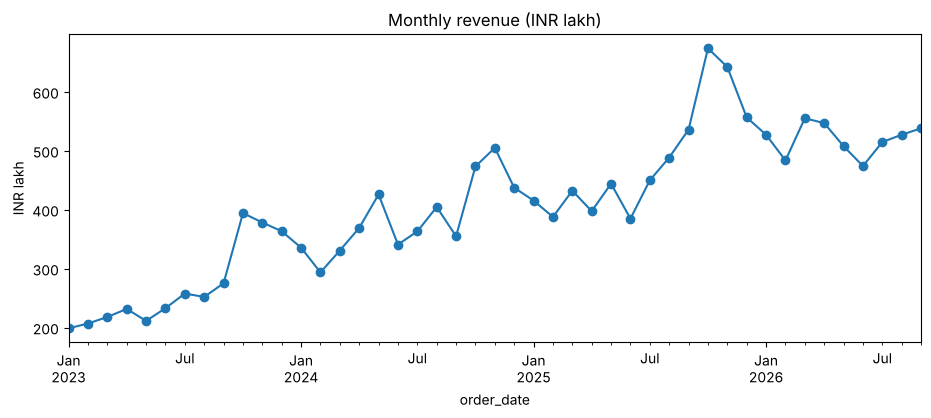

Kya dikhta hai: upar jaata trend + har saal Oct-Nov (festive) mein peak.


In [3]:
monthly = sales.set_index("order_date").resample("MS")["revenue"].sum() / 1e5
ax = monthly.plot(marker="o", title="Monthly revenue (INR lakh)")
ax.set_ylabel("INR lakh"); plt.show()
print("Kya dikhta hai: upar jaata trend + har saal Oct-Nov (festive) mein peak.")

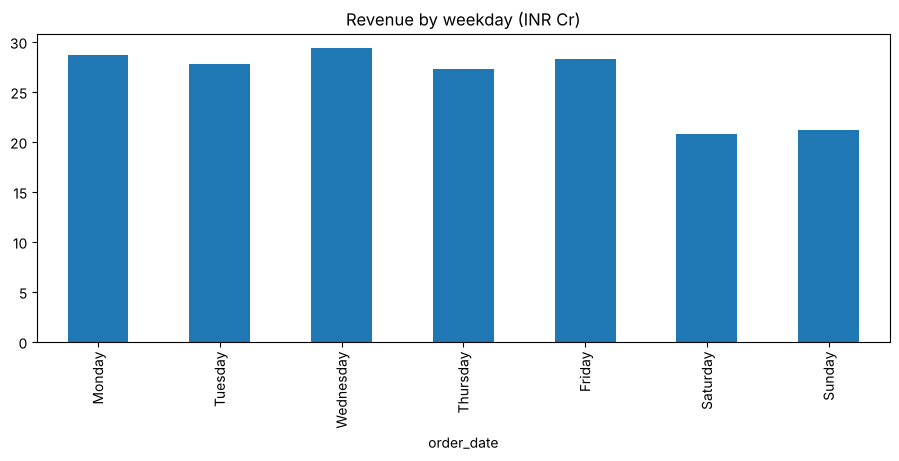

In [4]:
by_dow = sales.groupby(sales.order_date.dt.day_name())["revenue"].sum().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]) / 1e7
by_dow.plot(kind="bar", title="Revenue by weekday (INR Cr)"); plt.show()

EDA se 3 baatein mili jo model design mein kaam aayengi: **trend** (growth), **yearly seasonality**
(festive peak), **weekly pattern** (weekend dip). Model ke features inhi ko capture karne chahiye.

## 2. Forecasting problem frame karna
- Target: har region ki **daily revenue**, agle **30 din**
- Har feature sirf wo data use kare jo forecast ke din pata ho → isliye saare lags **≥ 30 din** purane
  (`lag_30`, `roll28_lag30` …). Isse ek hi model 30 din aage tak predict kar leta hai ("direct" strategy).

In [5]:
from src.ml import forecasting as F
daily = F.load_daily()
feats = F.build_features(daily)
feats.dropna().head()

,date,region,y,lag_30,lag_35,lag_364,roll7_lag30,roll28_lag30,roll91_lag30,ly_week_mean,ly_month_mean,ly_ratio,region_code,dow,doy,month,is_weekend
484,2024-04-29,East,412362.71,49273.34,28850.41,9960.69,175319.907143,151402.220357,157635.781648,126436.920000,118070.021000,1.176915,0,0,120,4,0
485,2024-04-30,East,248650.73,19344.71,426298.71,207113.38,162340.565714,147241.705000,156859.702857,136094.810000,117495.405667,1.165976,0,1,121,4,0
486,2024-05-01,East,525102.82,418897.26,81920.39,157223.71,218061.544286,159639.124643,159203.030879,115662.454286,118240.758000,1.137046,0,2,122,5,0
487,2024-05-02,East,422730.92,64562.25,422660.88,165293.59,166384.907143,150406.298214,155656.285714,104840.735714,121596.242333,1.179460,0,3,123,5,0
488,2024-05-03,East,403308.41,200852.62,108035.52,79887.64,183375.225714,156363.804643,157798.384725,139444.288571,114353.251333,1.120342,0,4,124,5,0


## 3. Pehle baseline, phir model — aur test ka sahi tareeka
**Rolling-origin backtest:** last 12 mahine, har mahine ke liye sirf us se pehle ke data par train karo
aur agle 30 din predict karo. Random train/test split time-series mein galat hai (future se past predict ho jaata).

Baselines:
- `naive_last30` = pichhle 30 din ka average
- `seasonal_naive` = pichhle saal same din × growth

### Experiment 1 (rejected): log(revenue) target
Pehla model `log1p(revenue)` par train kiya. Dekhiye har mahine error kis taraf hai:

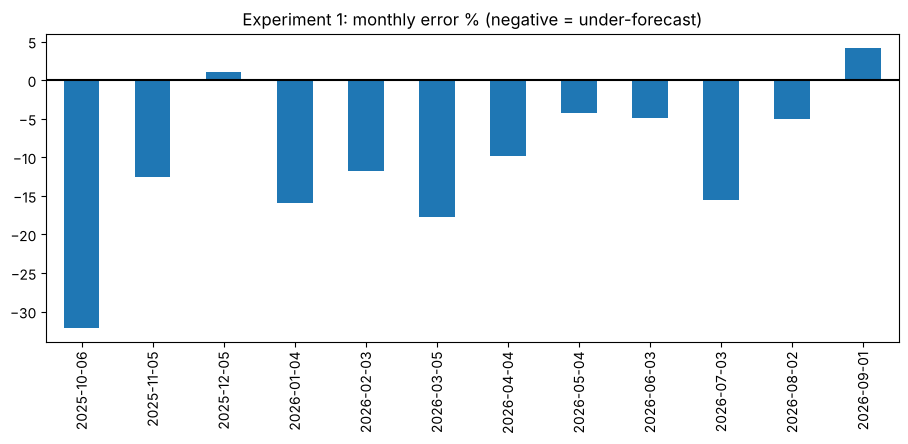

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor as HGB
errs = []
for cutoff in F.fold_cutoffs(daily):
    tr = feats[feats.date < cutoff].dropna(subset=F.FEATURES + ["y"])
    te = feats[(feats.date >= cutoff) & (feats.date < cutoff + pd.Timedelta(days=30))]
    m = HGB(max_iter=300, learning_rate=0.04, min_samples_leaf=30, categorical_features=[0],
            random_state=42).fit(tr[F.FEATURES], np.log1p(tr.y))
    p = np.expm1(m.predict(te[F.FEATURES]))
    errs.append(100 * (p.sum() / te.y.sum() - 1))
pd.Series(errs, index=[str(c.date()) for c in F.fold_cutoffs(daily)]).round(1).plot(
    kind="bar", title="Experiment 1: monthly error % (negative = under-forecast)"); plt.axhline(0, c="k"); plt.show()

Lagbhag har mahine **minus** mein → model systematically kam bata raha hai.
**Wajah:** log scale par average lena = *median* predict karna; revenue mein bade corporate orders hote hain,
isliye median < mean. Ye galti sirf backtest se pakdi gayi, accuracy number se nahi.

### Experiment 2 (final): revenue ÷ recent level, Poisson loss
- Target = `revenue / 91-day average` → model sirf *seasonal multiplier* seekhta hai, trend "level" sambhalta hai
  (trees future ka badhta trend extrapolate nahi kar paate)
- Poisson loss → predictions positive aur average par unbiased

In [7]:
bt = F.backtest(daily)
pd.DataFrame(bt["metrics"]).T[["monthly_total_wape", "weekly_total_wape", "weekly_region_wape", "daily_wape"]]

,monthly_total_wape,weekly_total_wape,weekly_region_wape,daily_wape
model,0.079,0.106,0.178,0.420
naive_last30,0.086,0.104,0.187,0.424
seasonal_naive,0.087,0.132,0.237,0.585


Final model monthly level par dono baselines se behtar hai. Weekly total par naive ke barabar hai —
ye honestly report karna zaroori hai. Daily error (~40%) high hai kyunki ek bada order ek din ko hila deta hai;
business decisions weekly/monthly par hote hain.

## 4. Churn prediction — leakage se kaise bache
**Snapshot method:** ek date (snapshot) chuno. Features = snapshot se *pehle* ka data.
Label = kya customer agle 90 din mein chala gaya. Kai snapshots → training data.

Train: 2025 ke snapshots · Validation (model choose karna): 2026-01-01 · Test (sirf ek baar dekha): 2026-06-30

In [8]:
from src.ml import churn as C
train = pd.concat([C.labelled(s, sales, cust, tickets) for s in C.TRAIN_SNAPSHOTS])
valid = C.labelled(C.VALID_SNAPSHOT, sales, cust, tickets)
print("train", train.shape, "churn rate", round(train.churned.mean(), 3))
train[["customer_id", "snapshot", "recency_days", "orders_90d", "order_trend", "neg_tickets_90d", "churned"]].head()

train (7902, 29) churn rate 0.031


,customer_id,snapshot,recency_days,orders_90d,order_trend,neg_tickets_90d,churned
0,C00001,2025-01-01,19.0,5.0,1.500,0.0,0
1,C00002,2025-01-01,60.0,1.0,1.000,0.0,0
2,C00004,2025-01-01,7.0,3.0,2.000,0.0,0
3,C00008,2025-01-01,19.0,1.0,2.000,1.0,0
4,C00009,2025-01-01,50.0,2.0,0.375,0.0,0


In [9]:
# churners vs non-churners: features mein fark dikhna chahiye
train.groupby("churned")[["orders_90d", "order_trend", "recency_days", "tickets_90d", "neg_tickets_90d"]].mean().round(2)

,orders_90d,order_trend,recency_days,tickets_90d,neg_tickets_90d
churned,,,,,
0,2.55,1.38,49.30,0.30,0.07
1,1.87,1.23,78.65,1.64,1.20


In [10]:
rows = {}
for name, model in C.build_models().items():
    model.fit(train[C.NUM + C.CAT], train.churned)
    p = model.predict_proba(valid[C.NUM + C.CAT])[:, 1]
    rows[name] = C.evaluate(valid.churned.values, p)
pd.DataFrame(rows).T

,roc_auc,pr_auc,churn_rate,mean_predicted_prob,precision_top10pct,recall_top10pct,lift_top10pct
logistic_regression,0.882,0.503,0.037,0.027,0.239,0.654,6.54
gradient_boosting,0.883,0.470,0.037,0.022,0.239,0.654,6.54


**Lesson — calibration:** pehle `class_weight="balanced"` lagaya tha. Ranking (ROC-AUC) same rahi, lekin
probabilities 10x phool gayi aur "revenue at risk" ₹10 Cr aa raha tha. Balanced weights hata kar
probabilities realistic hui. `mean_predicted_prob` vs `churn_rate` column isi ko check karta hai.

Precision@top-10% sabse useful metric hai: retention team itne hi log call kar sakti hai.

## 5. Segmentation — RFM + KMeans

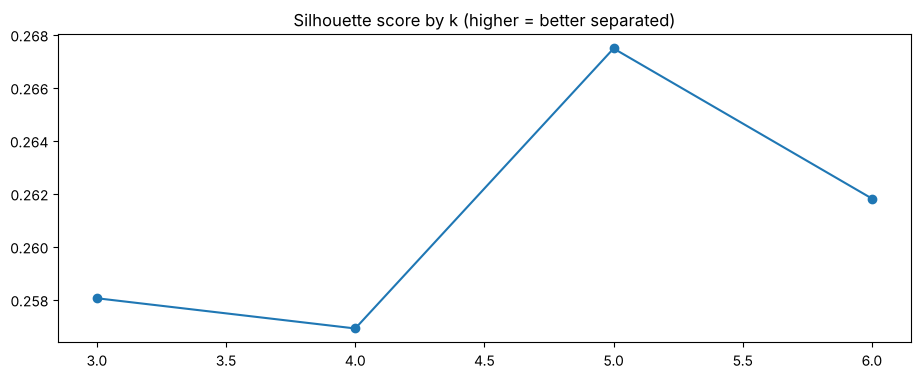

In [11]:
from src.ml import segmentation as S
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from src.ml.features import customer_features
f = customer_features(S.SNAPSHOT, sales, cust, tickets); f = f[f.orders_lifetime > 0]
X = np.log1p(f[S.RFM].assign(recency_days=f.recency_days.clip(upper=730)))
Xs = StandardScaler().fit_transform(X)
sil = {k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=42).fit_predict(Xs), sample_size=2000, random_state=42)
       for k in range(3, 7)}
pd.Series(sil).plot(marker="o", title="Silhouette score by k (higher = better separated)"); plt.show()

In [12]:
km = KMeans(5, n_init=10, random_state=42).fit(Xs); f["cluster"] = km.labels_
prof = f.groupby("cluster")[S.RFM].mean().round(0)
prof["name"] = prof.index.map(S.name_clusters(prof)); prof

,recency_days,orders_365d,revenue_365d,avg_order_value,name
cluster,,,,,
0,14.0,18.0,593817.0,33402.0,Champions
1,8.0,10.0,96327.0,9720.0,Loyal regulars
2,53.0,9.0,108927.0,12803.0,Occasional buyers
3,49.0,9.0,692777.0,76161.0,Big-ticket buyers
4,94.0,3.0,21007.0,8468.0,Slipping away


Cluster numbers (0–4) business ke liye bekaar hain, isliye har cluster ko uske RFM averages ke basis par
naam aur action diya (`name_clusters`). Pehla naming rule galat tha (sabse frequent buyers ko
"Big-ticket (low value)" bol raha tha) — output ko padhkar hi pakda.

## Summary — har ML step ka checklist
| Step | Kya karna | Is project mein |
|---|---|---|
| Frame | Business sawal + target + horizon | 30-day revenue, 90-day churn |
| EDA | Trend, seasonality, distributions | Festive peak, weekend dip |
| Split | Time-based, no leakage | Rolling folds, snapshots |
| Baseline | Simple rule | naive_last30, logistic regression |
| Model | Compare on same test | GB vs baselines, LR vs GB |
| Debug | Bias, calibration, sanity | log-target bias, class_weight |
| Ship | `src/` code + saved model + report | `run_pipeline.py` |